# Supplementary Fig. 4: Parameter recovery

[AI generated summary] Parameter recovery of the foraging (top), inferential RL (middle) and standard RL (bottom) models. For each model, 100 sessions of 10,000 trials are simulated with random parameters and fitted with the same model (these are the diagonal fits of the model recovery analysis, Supplementary Fig. 3). Scatter plots of the recovered vs. true parameters; red line: linear regression, dashed line: identity; titles: Pearson r and p.

**How to run:** run all cells (a few seconds). Figures are saved in `figs/` (one file per model). The titles of the paper figure were edited when the figure was assembled (`V0`: switch threshold τ; `stickiness_bias`: stickiness κ).

**Results:** precomputed results are provided in `results/behav_modeling/recovery` (see the README). To recompute them, run in this folder: `python run_model_recovery.py` (100 simulated sessions of 10,000 trials per model, each fitted with the 3 models; ~13 h on 20 CPUs).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from popy.config import RESULTS_PATH

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load results

In [3]:
# Load the model recovery results
results_path = os.path.join(RESULTS_PATH, "behav_modeling", "recovery", "model_recovery_10k.csv")
df = pd.read_csv(results_path)

# sort by model_true, iteration, model_fitted
df = df.sort_values(by=['model_true', 'iteration', 'model_fitted']).reset_index(drop=True)

# remove when beta < 5 or epsilon > .4
#df = df[(df["beta"] < 20) & (df["beta"] > 1)]

print(f"Loaded {len(df)} simulations")
df

Loaded 900 simulations


,model_true,model_fitted,iteration,alpha,beta,stickiness_bias,alpha_recovered,beta_recovered,stickiness_bias_recovered,LPT_best,V0,V0_recovered
0,Foraging,Foraging,0,0.429288,6.279654,NaN,0.358653,7.512074,NaN,0.511604,0.321244,0.352760
1,Foraging,Inferential RL - stickiness,0,0.429288,6.279654,NaN,0.730035,1.888728,1.576635,0.495589,0.321244,NaN
2,Foraging,Standard RL - stickiness,0,0.429288,6.279654,NaN,0.389118,2.785746,1.158414,0.464353,0.321244,NaN
3,Foraging,Foraging,1,0.350213,6.370626,NaN,0.321578,7.423149,NaN,0.686078,0.050051,0.108900
4,Foraging,Inferential RL - stickiness,1,0.350213,6.370626,NaN,0.635777,1.855338,2.821763,0.653605,0.050051,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
895,Standard RL - stickiness,Inferential RL - stickiness,98,0.371142,1.897931,1.071304,0.429187,1.204091,1.410533,0.435287,NaN,NaN
896,Standard RL - stickiness,Standard RL - stickiness,98,0.371142,1.897931,1.071304,0.675445,0.050000,1.371240,0.420998,NaN,NaN
897,Standard RL - stickiness,Foraging,99,0.213232,6.854237,0.076596,0.219369,6.396040,NaN,0.506596,NaN,0.263817
898,Standard RL - stickiness,Inferential RL - stickiness,99,0.213232,6.854237,0.076596,0.066522,8.206241,0.584239,0.543706,NaN,NaN


In [4]:
# remove all entries of WSLS
df = df[~df["model_true"].str.contains("WSLS")].reset_index(drop=True)
df = df[~df["model_fitted"].str.contains("WSLS")].reset_index(drop=True)

df

,model_true,model_fitted,iteration,alpha,beta,stickiness_bias,alpha_recovered,beta_recovered,stickiness_bias_recovered,LPT_best,V0,V0_recovered
0,Foraging,Foraging,0,0.429288,6.279654,NaN,0.358653,7.512074,NaN,0.511604,0.321244,0.352760
1,Foraging,Inferential RL - stickiness,0,0.429288,6.279654,NaN,0.730035,1.888728,1.576635,0.495589,0.321244,NaN
2,Foraging,Standard RL - stickiness,0,0.429288,6.279654,NaN,0.389118,2.785746,1.158414,0.464353,0.321244,NaN
3,Foraging,Foraging,1,0.350213,6.370626,NaN,0.321578,7.423149,NaN,0.686078,0.050051,0.108900
4,Foraging,Inferential RL - stickiness,1,0.350213,6.370626,NaN,0.635777,1.855338,2.821763,0.653605,0.050051,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
895,Standard RL - stickiness,Inferential RL - stickiness,98,0.371142,1.897931,1.071304,0.429187,1.204091,1.410533,0.435287,NaN,NaN
896,Standard RL - stickiness,Standard RL - stickiness,98,0.371142,1.897931,1.071304,0.675445,0.050000,1.371240,0.420998,NaN,NaN
897,Standard RL - stickiness,Foraging,99,0.213232,6.854237,0.076596,0.219369,6.396040,NaN,0.506596,NaN,0.263817
898,Standard RL - stickiness,Inferential RL - stickiness,99,0.213232,6.854237,0.076596,0.066522,8.206241,0.584239,0.543706,NaN,NaN


---
# Supplementary Fig. 4

Diagonal rows (parameter recovery): 300


,model_true,model_fitted,iteration,alpha,beta,stickiness_bias,alpha_recovered,beta_recovered,stickiness_bias_recovered,LPT_best,V0,V0_recovered
0,Foraging,Foraging,0,0.429288,6.279654,NaN,0.358653,7.512074,NaN,0.511604,0.321244,0.352760
3,Foraging,Foraging,1,0.350213,6.370626,NaN,0.321578,7.423149,NaN,0.686078,0.050051,0.108900
6,Foraging,Foraging,2,0.361597,3.988790,NaN,0.342569,4.155493,NaN,0.454579,0.245895,0.240599
9,Foraging,Foraging,3,0.430479,6.157539,NaN,0.414226,6.392551,NaN,0.593630,0.180907,0.180958
12,Foraging,Foraging,4,0.680218,3.961880,NaN,0.788190,3.395810,NaN,0.430696,0.487708,0.455558


Detected parameters: ['V0', 'alpha', 'beta', 'stickiness_bias']
Models (diagonal): ['Foraging', 'Inferential RL - stickiness', 'Standard RL - stickiness']
Foraging - alpha: r=0.89, p=1.5546322695324452e-34
Foraging - beta: r=0.70, p=7.333698726172779e-16
Foraging - V0: r=0.95, p=9.299289184573168e-52


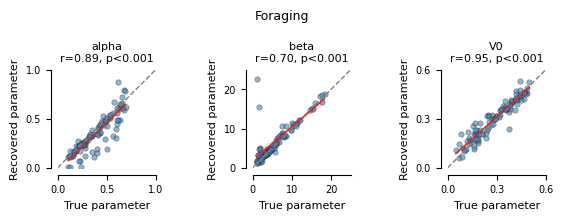

Inferential RL - stickiness - alpha: r=0.76, p=5.3413055467257134e-20
Inferential RL - stickiness - beta: r=0.99, p=6.404205783671646e-94
Inferential RL - stickiness - stickiness_bias: r=0.94, p=3.519149479909797e-47


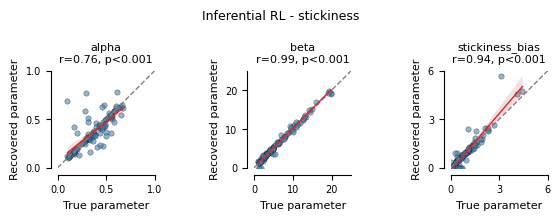

Standard RL - stickiness - alpha: r=0.73, p=1.272986726492464e-17
Standard RL - stickiness - beta: r=0.96, p=1.5436521692895773e-56
Standard RL - stickiness - stickiness_bias: r=0.99, p=3.932453530783439e-90


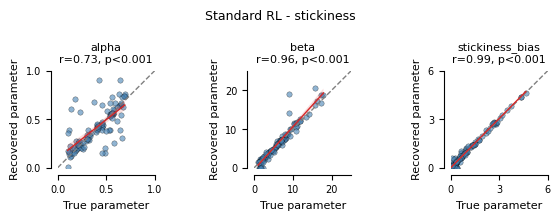

In [5]:
from scipy.stats import pearsonr

plt.rcParams.update({"font.size": 8})

# Diagonal only (same true & fitted model)
df_diag = df[df["model_true"] == df["model_fitted"]].copy()
print(f"Diagonal rows (parameter recovery): {len(df_diag)}")
display(df_diag.head())

# Infer parameter names from *_recovered columns
recovered_cols = [c for c in df_diag.columns if c.endswith("_recovered")]
param_names = [c.replace("_recovered", "") for c in recovered_cols if c.replace("_recovered", "") in df_diag.columns]
param_names = sorted(set(param_names))
print("Detected parameters:", param_names)

models = list(pd.unique(df_diag["model_true"]))
print("Models (diagonal):", models)

# One figure per model, one subplot per parameter
subplot_size = 2  # inches per subplot

ranges = {'alpha': (0, 1), 'beta': (0, 25), 'epsilon': (0, 1), 'stickiness_bias': (0, 6), 'V0': (0, .6)}

# Define nice tick values for each parameter
tick_values = {
    'alpha': [0, 0.5, 1.0],
    'beta': [0, 10, 20],
    'epsilon': [0, 0.5, 1.0],
    'stickiness_bias': [0, 3,  6],
    'V0': [0, 0.3, 0.6]
}

for model_name in models:
    df_m = df_diag[df_diag["model_true"] == model_name]

    # Keep only params that have data for this model
    model_params = []
    for p in param_names:
        if p in df_m.columns and f"{p}_recovered" in df_m.columns:
            if df_m[[p, f"{p}_recovered"]].dropna().shape[0] > 1:
                model_params.append(p)

    # sort alphabetically
    model_params = sorted(model_params, key=lambda x: (x != 'alpha', x != 'beta', x != 'epsilon', x != 'stickiness', x))

    if not model_params:
        continue

    n_params = len(model_params)
    fig, axes = plt.subplots(1, n_params, figsize=(subplot_size * n_params, subplot_size), squeeze=False)
    fig.suptitle(model_name, fontsize=9, y=1.02)

    for col_idx, p in enumerate(model_params):
        ax = axes[0, col_idx]
        sub = df_m[[p, f"{p}_recovered"]].dropna()
        x = sub[p].to_numpy()
        y = sub[f"{p}_recovered"].to_numpy()

        ax.scatter(x, y, alpha=0.6, s=15, edgecolors="black", linewidth=0.3, color="steelblue")

        # Shared axis limits
        '''lo = min(x.min(), y.min())
        hi = max(x.max(), y.max())
        pad = (hi - lo) * 0.05
        lim = (lo - pad, hi + pad)'''
        lim = ranges.get(p, (x.min(), x.max()))
        ax.set_xlim(lim)
        ax.set_ylim(lim)

        # Set matching ticks for both axes
        if p in tick_values:
            ticks = tick_values[p]
            ax.set_xticks(ticks)
            ax.set_yticks(ticks)

        # Identity line
        ax.plot(lim, lim, "grey", linewidth=1.0, linestyle="--", zorder=1)

        # Correlation + p-value
        r, pval = pearsonr(x, y)
        print(f"{model_name} - {p}: r={r:.2f}, p={pval}")
        # plot fit line
        sns.regplot(x=x, y=y, scatter=False, ax=ax, line_kws={"color": "tab:red", "linewidth": 1.0}, label='fit line')
        p_str = f"p<0.001" if pval < 0.001 else f"p={pval:.3f}"
        ax.set_title(f"{p}\nr={r:.2f}, {p_str}", fontsize=8)
        ax.set_xlabel(f"True parameter", fontsize=8)
        ax.set_ylabel(f"Recovered parameter", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.set_aspect("equal", adjustable="box")

        sns.despine(ax=ax)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))

    plt.tight_layout()

    # save as svg, transparent background, dpi 300
    plt.savefig(os.path.join(FIGS_PATH, f"figS4_parameter_recovery_{model_name}.svg"), format='svg', dpi=300, bbox_inches='tight')

    plt.show()

In [6]:
# Export source data (Supplementary Figure 4)
from popy.source_data import export_source_data

# scatter points (true and recovered parameter of each simulated session), per model, as selected in the plotting cell above
param_labels = {'alpha': 'learning rate (alpha)', 'beta': 'inverse temperature (beta)',
                'V0': 'switch threshold (tau; V0 in the code)', 'stickiness_bias': 'stickiness (kappa)'}
tables_s4, stats_s4 = {}, []
for model_name in models:
    df_m = df_diag[df_diag["model_true"] == model_name]
    model_params = [p for p in param_names if df_m[[p, f"{p}_recovered"]].dropna().shape[0] > 1]
    model_params = sorted(model_params, key=lambda x: (x != 'alpha', x != 'beta', x != 'epsilon', x != 'stickiness', x))
    label = model_name.replace(" - stickiness", "")
    table = df_m[['iteration'] + [c for p in model_params for c in (p, f'{p}_recovered')]].dropna()
    table = table.rename(columns={'iteration': 'Simulated session'})
    table = table.rename(columns={**{p: f'True {param_labels[p]}' for p in model_params},
                                  **{f'{p}_recovered': f'Recovered {param_labels[p]}' for p in model_params}})
    tables_s4[f'{label} model: true and recovered parameters'] = table
    for p in model_params:
        sub = df_m[[p, f"{p}_recovered"]].dropna()
        r, pval = pearsonr(sub[p], sub[f"{p}_recovered"])
        slope, intercept = np.polyfit(sub[p], sub[f"{p}_recovered"], 1)
        stats_s4.append({'Model': label, 'Parameter': param_labels[p], 'n': len(sub), 'Pearson r': r, 'p': pval,
                         'Regression line slope': slope, 'Regression line intercept': intercept})
tables_s4['Pearson correlation and linear regression (red line) of recovered vs. true parameters'] = pd.DataFrame(stats_s4)
export_source_data('Supplementary Figure 4', tables_s4,
                   'Parameter recovery: for each model, 100 sessions of 10,000 trials were simulated with random parameters and fitted with the '
                   'same model (maximum likelihood). Scatter points: true and recovered parameter of each simulated session (n = 100 per model). '
                   'Red line: least-squares linear regression (shaded band in the figure: its 95% bootstrap confidence interval, seaborn regplot); '
                   'r, p: Pearson correlation (two-sided).')

Supplementary Figure 4: source data saved (100 rows, 100 rows, 100 rows, 9 rows)
